# V4 Benchmark Rebuild + Zero-Shot Model Sweep

**Motivation (from V5.2 critique)**
- V3 benchmark uses group-only labels; V5.2 trains on group+category → systematic label mismatch causes v3 Spearman to appear near-chance even for good models.
- Holdout/borderline were generated with the same filter as training → in-distribution, ROC-AUC 0.994 is not a generalisation signal.
- The only genuine result was the adversarial test (ROC-AUC 0.977).

**This notebook**
1. Rebuilds the benchmark with **consistent labels** matching V5.2 training (group + Category, TF-IDF ≤ 0.30).
2. Also builds a **resolution-code benchmark** — tests whether tickets resolved the same way are semantically similar.
3. Also builds a **semantic benchmark** using resolution notes TF-IDF as ground truth.
4. Runs a **zero-shot sweep** of 7+ models and compares them on all three benchmarks.

| Model | Notes |
|-------|-------|
| Base MPNet (`all-mpnet-base-v2`) | Untrained baseline |
| V4 Cosine (production) | Previously deployed |
| V5.2 Merged (latest) | Best trained model so far |
| `BAAI/bge-base-en-v1.5` | Hard-neg trained, 768-dim |
| `intfloat/e5-base-v2` | Instruction-tuned retrieval, 768-dim |
| `nomic-ai/nomic-embed-text-v1.5` | Large diverse training, 768-dim |

In [1]:
# ── 1. Imports & Paths ─────────────────────────────────────────────────────
import json
import gc
import random
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy.stats import spearmanr
from tqdm.auto import tqdm
from sentence_transformers import SentenceTransformer
import torch

SEED = 42
random.seed(SEED); np.random.seed(SEED)

BASE      = Path(r'c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism')
DATA_NEW  = BASE / 'data_new'
CSV_PATH  = DATA_NEW / 'SNow_incident_ticket_data.csv'
MODELS_DIR = BASE / 'models' / 'real_servicenow_finetuned_mpnet_lora'

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')

OUT_v4   = DATA_NEW / 'benchmark_v4_group_category.json'
OUT_rcode = DATA_NEW / 'benchmark_v4_resolution_code.json'
RESULTS_PATH = BASE / 'models' / 'eval_v3_results' / 'zero_shot_sweep_v4.json'
RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)

Device: cuda


In [2]:
# ── 2. Load & Prepare Data ─────────────────────────────────────────────────
df = pd.read_csv(CSV_PATH, encoding='utf-8', encoding_errors='replace')
print(f'Total rows: {len(df)}')

# Minimal text cleaning
df['Description'] = df['Description'].fillna('').str.strip()
df['Resolution notes'] = df['Resolution notes'].fillna('').str.strip()

# Build context-enriched text (matches training format from Cell 4 of training notebook)
def build_text(row):
    parts = []
    parts.append(f"Category: {row.get('Category', '')}")
    parts.append(f"Service: {row.get('Service', '')}")
    parts.append(f"Priority: {row.get('Priority', '')}")
    desc = str(row.get('Description', '')).strip()
    if desc:
        parts.append(f"Description: {desc}")
    return ' | '.join(p for p in parts if p.split(': ')[1].strip())

df['text'] = df.apply(build_text, axis=1)

# Drop short texts
df = df[df['text'].str.len() >= 25].reset_index(drop=True)
print(f'After length filter: {len(df)}')
print(f'Assignment groups : {df["Assignment group"].nunique()}')
print(f'Categories        : {df["Category"].nunique()} — {df["Category"].value_counts().to_dict()}')
print(f'Resolution codes  : {df["Resolution code"].nunique()}')
print(f'Top resolution codes:')
print(df['Resolution code'].value_counts().head(8).to_string())

Total rows: 10633
After length filter: 10633
Assignment groups : 26
Categories        : 4 — {'Application/Software': 9570, 'Network': 372, 'Server': 123, 'Hardware': 5}
Resolution codes  : 11
Top resolution codes:
Resolution code
Solved (Permanently)            2742
Resolved by Workaround          1958
Closed/Resolved by Requester    1663
Not an Incident                 1514
Duplicate                        785
Resolved by Change               619
User Error                       604
Resolved by Service Request      303


In [3]:
# ── 3. TF-IDF Gate Helper ─────────────────────────────────────────────────
class _TFIDFCalc:
    def __init__(self, texts, max_features=15000):
        print('Building TF-IDF...')
        self._vec = TfidfVectorizer(
            max_features=max_features, stop_words='english',
            ngram_range=(1, 2), min_df=2, max_df=0.95
        )
        self._mat = self._vec.fit_transform(texts)
        print(f'  TF-IDF matrix: {self._mat.shape}')

    def sim(self, i, j):
        return float((self._mat[i] @ self._mat[j].T).toarray()[0][0])


# ── 4. Benchmark Builder ───────────────────────────────────────────────────
def build_benchmark(
    df, label_col, label_fn,
    target_pairs=950, pos_frac=0.5,
    pos_gate=0.30, neg_gate=0.35,
    hard_neg_svc=True,
    seed=42, desc='benchmark'
):
    """
    Build a balanced benchmark with pos_gate / neg_gate TF-IDF constraints.

    label_fn(row_i, row_j) -> True (positive) | False (negative)
    hard_neg_svc: if True, draw negatives from same Service first (harder).
    """
    rng   = np.random.RandomState(seed)
    tfidf = _TFIDFCalc(df['Description'].fillna('').tolist())

    pos_target = int(target_pairs * pos_frac)
    neg_target = target_pairs - pos_target

    # Index maps
    label_groups = {}
    for idx, row in df.iterrows():
        k = row[label_col]
        if pd.notna(k):
            label_groups.setdefault(k, []).append(idx)
    label_groups = {k: v for k, v in label_groups.items() if len(v) >= 2}

    svc_idx = {s: list(ix) for s, ix in df.groupby('Service').groups.items()}
    all_idx = list(df.index)

    pairs = []

    # Positives
    pbar = tqdm(total=pos_target, desc=f'[{desc}] positives')
    attempts = 0
    while len(pairs) < pos_target and attempts < pos_target * 200:
        attempts += 1
        k  = rng.choice(list(label_groups.keys()))
        ij = rng.choice(label_groups[k], 2, replace=False)
        i, j = int(ij[0]), int(ij[1])
        if label_fn(df.loc[i], df.loc[j]) and tfidf.sim(i, j) <= pos_gate:
            pairs.append({'text1': df.at[i, 'text'], 'text2': df.at[j, 'text'],
                          'label': 1, 'tier': 'positive'})
            pbar.update(1)
    pbar.close()
    print(f'  Positives: {sum(p["label"]==1 for p in pairs)}/{pos_target}')

    # Hard negatives (cross-label, same service if hard_neg_svc, TF-IDF ≥ neg_gate threshold region)
    neg_pairs = []
    pbar = tqdm(total=neg_target, desc=f'[{desc}] negatives')
    attempts = 0
    while len(neg_pairs) < neg_target and attempts < neg_target * 200:
        attempts += 1
        i = int(rng.choice(all_idx))
        row_i = df.loc[i]
        if hard_neg_svc:
            pool = svc_idx.get(row_i['Service'], all_idx)
        else:
            pool = all_idx
        j = int(rng.choice(pool))
        if i == j: continue
        row_j = df.loc[j]
        if label_fn(row_i, row_j): continue  # positive pair — skip
        if tfidf.sim(i, j) <= neg_gate:
            neg_pairs.append({'text1': df.at[i, 'text'], 'text2': df.at[j, 'text'],
                              'label': 0, 'tier': 'hard_neg' if hard_neg_svc else 'easy_neg'})
            pbar.update(1)
    pbar.close()
    print(f'  Negatives: {len(neg_pairs)}/{neg_target}')

    pairs += neg_pairs
    rng.shuffle(pairs)
    del tfidf; gc.collect()
    return pairs

print('Helpers defined.')

Helpers defined.


In [4]:
# ── 5. Build V4 Benchmark: Group + Category (matching V5.2 training labels) ─
print('='*60)
print('Building V4 benchmark — group + Category joint label')
print('  pos_gate=0.30  neg_gate=0.35  target=950 pairs')
print('='*60)

def label_group_cat(ri, rj):
    """True iff same Assignment group AND same Category (both non-null)."""
    g1, g2 = ri['Assignment group'], rj['Assignment group']
    c1, c2 = ri['Category'], rj['Category']
    if pd.isna(g1) or pd.isna(g2) or pd.isna(c1) or pd.isna(c2): return False
    return g1 == g2 and c1 == c2

if OUT_v4.exists():
    print(f'[LOAD] {OUT_v4}')
    v4_pairs = json.loads(OUT_v4.read_text(encoding='utf-8'))
else:
    v4_pairs = build_benchmark(
        df, label_col='Assignment group',
        label_fn=label_group_cat,
        target_pairs=950, pos_frac=0.5,
        pos_gate=0.30, neg_gate=0.35,
        hard_neg_svc=True, seed=SEED, desc='v4-group+cat'
    )
    OUT_v4.write_text(json.dumps(v4_pairs, ensure_ascii=False), encoding='utf-8')
    print(f'[SAVE] {OUT_v4}')

pos_n = sum(p['label']==1 for p in v4_pairs)
print(f'\nV4 benchmark: {len(v4_pairs)} pairs | pos={pos_n} neg={len(v4_pairs)-pos_n}')

Building V4 benchmark — group + Category joint label
  pos_gate=0.30  neg_gate=0.35  target=950 pairs
[LOAD] c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\data_new\benchmark_v4_group_category.json

V4 benchmark: 950 pairs | pos=475 neg=475


In [5]:
# ── 6. Build Resolution-Code Benchmark ─────────────────────────────────────
# Resolution code is 100% filled, 11 distinct values — tests whether tickets
# resolved the same way (e.g. "Solved (Permanently)") are semantically similar.
# Positives: same resolution code, TF-IDF ≤ 0.30
# The hypothesis: an analyst searching for reusable resolutions cares about
# resolution-similarity more than routing-similarity.

# Filter to resolution codes with enough examples (≥ 20)
freq = df['Resolution code'].value_counts()
valid_codes = set(freq[freq >= 20].index)
df_rc = df[df['Resolution code'].isin(valid_codes)].reset_index(drop=True)
print(f'Resolution code benchmark — {len(df_rc)} rows with ≥20-member codes')
print(f'Valid codes ({len(valid_codes)}): {sorted(valid_codes)}')

def label_rescode(ri, rj):
    rc1, rc2 = ri['Resolution code'], rj['Resolution code']
    if pd.isna(rc1) or pd.isna(rc2): return False
    return rc1 == rc2

if OUT_rcode.exists():
    print(f'[LOAD] {OUT_rcode}')
    rcode_pairs = json.loads(OUT_rcode.read_text(encoding='utf-8'))
else:
    rcode_pairs = build_benchmark(
        df_rc, label_col='Resolution code',
        label_fn=label_rescode,
        target_pairs=950, pos_frac=0.5,
        pos_gate=0.30, neg_gate=0.35,
        hard_neg_svc=False,  # resolution codes cut across services
        seed=SEED, desc='v4-rescode'
    )
    OUT_rcode.write_text(json.dumps(rcode_pairs, ensure_ascii=False), encoding='utf-8')
    print(f'[SAVE] {OUT_rcode}')

pos_n = sum(p['label']==1 for p in rcode_pairs)
print(f'\nResolution-code benchmark: {len(rcode_pairs)} pairs | pos={pos_n} neg={len(rcode_pairs)-pos_n}')

Resolution code benchmark — 10446 rows with ≥20-member codes
Valid codes (10): ['Closed/Resolved by Requester', 'Duplicate', 'Not Solved (Not Reproducible)', 'Not an Incident', 'Resolved by Change', 'Resolved by Problem', 'Resolved by Service Request', 'Resolved by Workaround', 'Solved (Permanently)', 'User Error']
[LOAD] c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\data_new\benchmark_v4_resolution_code.json

Resolution-code benchmark: 950 pairs | pos=475 neg=475


In [6]:
# -- 7. Evaluation Helper ---------------------------------------------------
def _is_oom_error(exc: Exception) -> bool:
    msg = str(exc).lower()
    return ('out of memory' in msg) or ('cuda error: out of memory' in msg)


def eval_model_on_benchmark(
    model,
    pairs,
    batch_size=16,
    prefix_query='',
    prefix_doc='',
    allow_oom_retry=True,
):
    """
    Encode all pairs and compute Spearman, ROC-AUC, PR-AUC.
    Retries with smaller batch sizes on CUDA OOM.
    """
    texts1 = [prefix_query + p['text1'] for p in pairs]
    texts2 = [prefix_doc + p['text2'] for p in pairs]
    labels = np.array([p['label'] for p in pairs], dtype=float)

    retry_batches = [batch_size]
    if allow_oom_retry:
        for b in (16, 8, 4, 2):
            if b < batch_size and b not in retry_batches:
                retry_batches.append(b)

    last_err = None
    for bsz in retry_batches:
        try:
            emb1 = model.encode(
                texts1,
                batch_size=bsz,
                show_progress_bar=True,
                convert_to_numpy=True,
                normalize_embeddings=True,
            )
            emb2 = model.encode(
                texts2,
                batch_size=bsz,
                show_progress_bar=True,
                convert_to_numpy=True,
                normalize_embeddings=True,
            )
            scores = (emb1 * emb2).sum(axis=1)  # dot = cosine when normalized
            del emb1, emb2
            break
        except Exception as e:
            last_err = e
            if _is_oom_error(e):
                print(f'  [OOM] encode failed at batch={bsz}; retrying smaller batch...')
                if DEVICE == 'cuda':
                    torch.cuda.empty_cache()
                gc.collect()
                continue
            raise
    else:
        raise RuntimeError(f'Encoding failed after OOM retries: {last_err}')

    spearman, _ = spearmanr(labels, scores)
    roc_auc = roc_auc_score(labels, scores)
    pr_auc = average_precision_score(labels, scores)
    pos_mean = float(scores[labels == 1].mean())
    neg_mean = float(scores[labels == 0].mean())
    delta = pos_mean - neg_mean

    return {
        'spearman': round(float(spearman), 4),
        'roc_auc': round(float(roc_auc), 4),
        'pr_auc': round(float(pr_auc), 4),
        'pos_mean': round(pos_mean, 4),
        'neg_mean': round(neg_mean, 4),
        'delta': round(delta, 4),
        'batch_used': bsz,
    }


# Models to sweep
NOMIC_V53_PATH = str(BASE / 'models' / 'real_servicenow_finetuned_nomic_lora' / 'real_servicenow_v2_20260302_1754_merged')

SWEEP = [
    {
        'name': 'Base MPNet',
        'path': 'sentence-transformers/all-mpnet-base-v2',
        'prefix_query': '',
        'prefix_doc': '',
        'batch_size': 16,
    },
    {
        'name': 'V4 Cosine (production)',
        'path': str(MODELS_DIR / 'real_servicenow_v2_20260104_2321'),
        'prefix_query': '',
        'prefix_doc': '',
        'batch_size': 16,
    },
    {
        'name': 'V5.2 Merged (latest)',
        'path': str(MODELS_DIR / 'real_servicenow_v2_20260225_1841_merged'),
        'prefix_query': '',
        'prefix_doc': '',
        'batch_size': 16,
    },
    {
        'name': 'V5.3 Nomic (fine-tuned)',
        'path': NOMIC_V53_PATH,
        'prefix_query': 'search_query: ',
        'prefix_doc': 'search_document: ',
        'trust_remote_code': True,
        'batch_size': 8,
    },
    {
        'name': 'BGE-base-en-v1.5',
        'path': 'BAAI/bge-base-en-v1.5',
        'prefix_query': 'Represent this sentence for searching relevant passages: ',
        'prefix_doc': '',
        'batch_size': 16,
    },
    {
        'name': 'E5-base-v2',
        'path': 'intfloat/e5-base-v2',
        'prefix_query': 'query: ',
        'prefix_doc': 'passage: ',
        'batch_size': 16,
    },
    {
        'name': 'Nomic-embed-text-v1.5',
        'path': 'nomic-ai/nomic-embed-text-v1.5',
        'prefix_query': 'search_query: ',
        'prefix_doc': 'search_document: ',
        'trust_remote_code': True,
        'batch_size': 8,
    },
]

print(f'Sweep: {len(SWEEP)} models')
print(f'V5.3 Nomic path: {NOMIC_V53_PATH}')

# Validate V5.3 path existence
if not Path(NOMIC_V53_PATH).exists():
    print(f'WARNING: V5.3 Nomic path does not exist: {NOMIC_V53_PATH}')
    print('This model may be skipped during sweep.')

Sweep: 7 models
V5.3 Nomic path: c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\real_servicenow_finetuned_nomic_lora\real_servicenow_v2_20260302_1754_merged


In [7]:
# -- 8. Run Sweep -----------------------------------------------------------
results = {}  # {model_name: {benchmark: metrics}}

benchmarks = {
    'v4_group_cat': v4_pairs,
    'v4_rescode': rcode_pairs,
}

for spec in SWEEP:
    name = spec['name']
    print(f'\n{"="*60}')
    print(f'Loading: {name}')
    print('=' * 60)

    try:
        kwargs = {'device': DEVICE}
        if spec.get('trust_remote_code'):
            kwargs['trust_remote_code'] = True
        m = SentenceTransformer(spec['path'], **kwargs)
    except Exception as e:
        print(f'[SKIP] Failed to load {name}: {e}')
        results[name] = {'error': str(e)}
        continue

    results[name] = {}
    for bname, bpairs in benchmarks.items():
        print(f'\n  Evaluating on {bname} ({len(bpairs)} pairs)...')
        try:
            metrics = eval_model_on_benchmark(
                m,
                bpairs,
                batch_size=spec.get('batch_size', 16),
                prefix_query=spec.get('prefix_query', ''),
                prefix_doc=spec.get('prefix_doc', ''),
            )
            results[name][bname] = metrics
            print(
                f'  Spearman={metrics["spearman"]:.4f}  '
                f'ROC-AUC={metrics["roc_auc"]:.4f}  '
                f'Delta={metrics["delta"]:+.4f}  '
                f'batch={metrics.get("batch_used", spec.get("batch_size", 16))}'
            )
        except Exception as e:
            print(f'  [ERROR] {e}')
            results[name][bname] = {'error': str(e)}

    del m
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()
    gc.collect()

# Save results
RESULTS_PATH.write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding='utf-8')
print(f'\n[SAVE] Results -> {RESULTS_PATH}')


Loading: Base MPNet


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



  Evaluating on v4_group_cat (950 pairs)...


Batches:   0%|          | 0/60 [00:00<?, ?it/s]

Batches:   0%|          | 0/60 [00:00<?, ?it/s]

... (53 outputs left out)

  Spearman=0.0248  ROC-AUC=0.5143  Delta=+0.0018  batch=8

  Evaluating on v4_rescode (950 pairs)...


Batches:   0%|          | 0/119 [00:00<?, ?it/s]

Batches:   0%|          | 0/119 [00:00<?, ?it/s]

  Spearman=0.1258  ROC-AUC=0.5726  Delta=+0.0218  batch=8

[SAVE] Results -> c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\eval_v3_results\zero_shot_sweep_v4.json


In [8]:
# ── 9. Results Table ───────────────────────────────────────────────────────
rows = []
for model_name, bmark_results in results.items():
    if 'error' in bmark_results:
        rows.append({'Model': model_name, 'Benchmark': 'N/A',
                     'Spearman': None, 'ROC-AUC': None, 'Δ(pos-neg)': None})
        continue
    for bname, metrics in bmark_results.items():
        if 'error' in metrics:
            rows.append({'Model': model_name, 'Benchmark': bname,
                         'Spearman': None, 'ROC-AUC': None, 'Δ(pos-neg)': None})
        else:
            rows.append({
                'Model'     : model_name,
                'Benchmark' : bname,
                'Spearman'  : metrics['spearman'],
                'ROC-AUC'   : metrics['roc_auc'],
                'PR-AUC'    : metrics['pr_auc'],
                'Δ(pos-neg)': metrics['delta'],
                'pos_mean'  : metrics['pos_mean'],
                'neg_mean'  : metrics['neg_mean'],
            })

df_res = pd.DataFrame(rows)

print('\n' + '='*80)
print('ZERO-SHOT SWEEP RESULTS')
print('='*80)

for bname in df_res['Benchmark'].unique():
    sub = df_res[df_res['Benchmark'] == bname].copy()
    sub = sub.drop('Benchmark', axis=1).sort_values('Spearman', ascending=False)
    print(f'\n── Benchmark: {bname} ──')
    print(sub.to_string(index=False))

print('\n' + '='*80)
print('VERDICT')
print('='*80)

try:
    v4_sub = df_res[df_res['Benchmark'] == 'v4_group_cat'].set_index('Model')
    best = v4_sub['Spearman'].idxmax()
    best_sp = v4_sub.loc[best, 'Spearman']
    v52_sp  = v4_sub.loc['V5.2 Merged (latest)', 'Spearman'] if 'V5.2 Merged (latest)' in v4_sub.index else None
    base_sp = v4_sub.loc['Base MPNet', 'Spearman'] if 'Base MPNet' in v4_sub.index else None

    print(f'Best model on v4_group_cat : {best} (Spearman={best_sp:.4f})')
    if v52_sp: print(f'V5.2 vs best              : {v52_sp:.4f} vs {best_sp:.4f}')
    if base_sp: print(f'V5.2 vs Base MPNet        : {v52_sp:.4f} vs {base_sp:.4f}')

    new_models = [s['name'] for s in SWEEP if s['name'] not in ('Base MPNet', 'V4 Cosine (production)', 'V5.2 Merged (latest)')]
    for nm in new_models:
        if nm in v4_sub.index:
            nm_sp = v4_sub.loc[nm, 'Spearman']
            if v52_sp and nm_sp > v52_sp:
                print(f'  [PIVOT] {nm} beats V5.2 ({nm_sp:.4f} > {v52_sp:.4f}) — consider fine-tuning on top of this base')
            else:
                print(f'  [OK]    {nm} ({nm_sp:.4f}) — V5.2 is competitive')
except Exception as e:
    print(f'Verdict error: {e}')


ZERO-SHOT SWEEP RESULTS

── Benchmark: v4_group_cat ──
                  Model  Spearman  ROC-AUC  PR-AUC  Δ(pos-neg)  pos_mean  neg_mean
V5.3 Nomic (fine-tuned)    0.0277   0.5160  0.5110      0.0050    0.6486    0.6436
  Nomic-embed-text-v1.5    0.0248   0.5143  0.4898      0.0018    0.7724    0.7706
             E5-base-v2   -0.0150   0.4913  0.4772     -0.0028    0.8383    0.8412
   V5.2 Merged (latest)   -0.0223   0.4871  0.4969     -0.0137    0.6999    0.7136
       BGE-base-en-v1.5   -0.0327   0.4811  0.4714     -0.0115    0.6790    0.6906
 V4 Cosine (production)   -0.0913   0.4473  0.4557     -0.0354    0.5000    0.5354
             Base MPNet   -0.0922   0.4468  0.4559     -0.0351    0.4997    0.5349

── Benchmark: v4_rescode ──
                  Model  Spearman  ROC-AUC  PR-AUC  Δ(pos-neg)  pos_mean  neg_mean
  Nomic-embed-text-v1.5    0.1258   0.5726  0.5596      0.0218    0.7395    0.7177
V5.3 Nomic (fine-tuned)    0.1162   0.5671  0.5497      0.0422    0.5492    0.5070
  

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (13 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: intfloat/e5-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: intfloat/e5-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
<All keys matched successfully>
<All keys matched successfully>


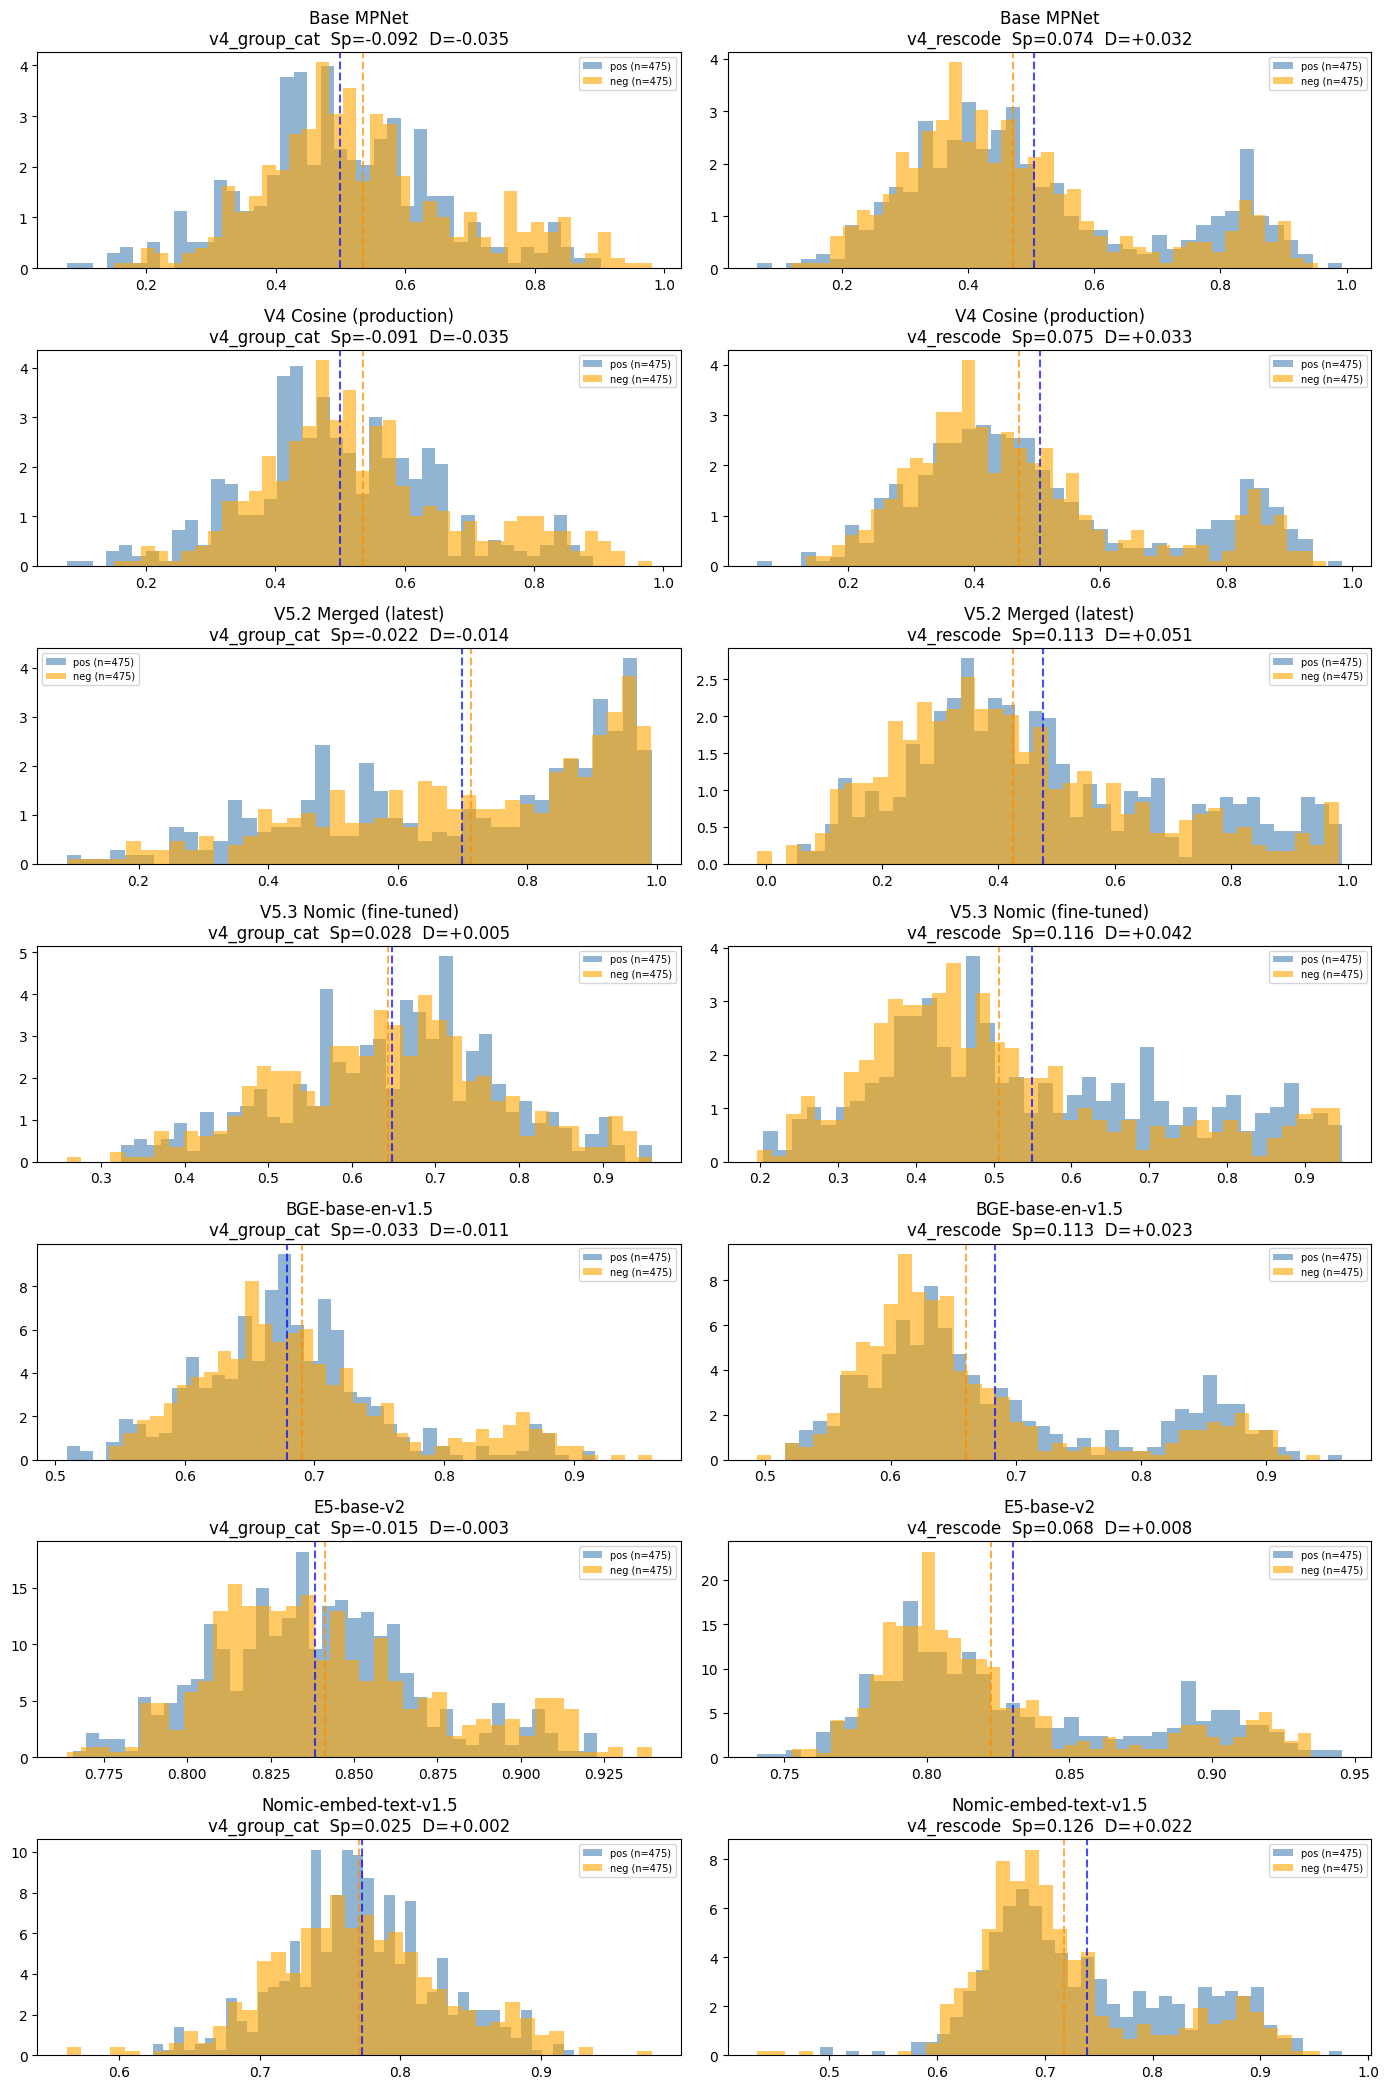

[SAVE] c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\eval_v3_results\zero_shot_distributions.png


In [9]:
# -- 10. Score Distribution Plot --------------------------------------------
import matplotlib.pyplot as plt

# Run plotting encodes on CPU to avoid GPU fragmentation and OOM after sweeps.
PLOT_DEVICE = 'cpu'

fig, axes = plt.subplots(len(SWEEP), 2, figsize=(14, 3 * len(SWEEP)), squeeze=False)
benchmark_list = list(benchmarks.items())

for row_idx, spec in enumerate(SWEEP):
    name = spec['name']
    for col_idx, (bname, bpairs) in enumerate(benchmark_list):
        ax = axes[row_idx][col_idx]
        bm = results.get(name, {}).get(bname, {})
        if 'error' in bm or not bm:
            ax.set_title(f'{name}\n{bname} - N/A')
            ax.axis('off')
            continue

        try:
            kwargs = {'device': PLOT_DEVICE}
            if spec.get('trust_remote_code'):
                kwargs['trust_remote_code'] = True
            m = SentenceTransformer(spec['path'], **kwargs)

            texts1 = [spec.get('prefix_query', '') + p['text1'] for p in bpairs]
            texts2 = [spec.get('prefix_doc', '') + p['text2'] for p in bpairs]
            labels = np.array([p['label'] for p in bpairs])

            e1 = m.encode(
                texts1,
                batch_size=min(spec.get('batch_size', 16), 8),
                convert_to_numpy=True,
                normalize_embeddings=True,
                show_progress_bar=False,
            )
            e2 = m.encode(
                texts2,
                batch_size=min(spec.get('batch_size', 16), 8),
                convert_to_numpy=True,
                normalize_embeddings=True,
                show_progress_bar=False,
            )
            scores = (e1 * e2).sum(axis=1)

            del m, e1, e2
            gc.collect()

            ax.hist(scores[labels == 1], bins=40, alpha=0.6, color='steelblue', label=f'pos (n={labels.sum()})', density=True)
            ax.hist(scores[labels == 0], bins=40, alpha=0.6, color='orange', label=f'neg (n={(labels == 0).sum()})', density=True)
            ax.axvline(bm['pos_mean'], color='blue', linestyle='--', alpha=0.7)
            ax.axvline(bm['neg_mean'], color='darkorange', linestyle='--', alpha=0.7)
            ax.set_title(f'{name}\n{bname}  Sp={bm["spearman"]:.3f}  D={bm["delta"]:+.3f}')
            ax.legend(fontsize=7)
        except Exception as e:
            ax.set_title(f'{name}\n{bname} - plot error')
            ax.text(0.5, 0.5, str(e), transform=ax.transAxes, fontsize=7)

plt.tight_layout()
plot_path = RESULTS_PATH.parent / 'zero_shot_distributions.png'
plt.savefig(plot_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'[SAVE] {plot_path}')

In [10]:

# ── 11. Build Semantic Benchmark: Resolution-Notes TF-IDF Ground Truth ─────
#
# Motivation: Previous benchmarks use routing labels (group+category) or
# coarse resolution codes — neither correlates reliably with description
# semantics. Here we use TF-IDF cosine similarity of RESOLUTION NOTES as
# the ground truth signal.
#
# Positive pair  : res_notes_tfidf_sim(i,j) >= 0.15  →  similar solutions
# Negative pair  : res_notes_tfidf_sim(i,j) <= 0.03  →  clearly different solutions
# Extra gate     : description_tfidf_sim(i,j) <= 0.40 on positives
#                  (prevents copy-paste tickets from trivially inflating cosine)
# Min note length: 80 chars — removes stubs like "Closed by Caller"
#
# The hypothesis: a model that genuinely understands ITSM semantics should
# score description pairs higher when their resolutions are similar,
# even though it never sees the resolution notes at inference time.

OUT_semantic = DATA_NEW / 'benchmark_v4_semantic_resnotes.json'

def build_semantic_benchmark(
    df, target_pairs=950, pos_frac=0.5,
    pos_rn_threshold=0.15,   # min res-notes TF-IDF sim to be positive
    neg_rn_threshold=0.03,   # max res-notes TF-IDF sim to be negative
    desc_gate=0.40,           # max description TF-IDF sim on positives (anti-duplicate gate)
    min_note_len=80,          # minimum resolution notes length to enter pool
    seed=42
):
    rng = np.random.RandomState(seed)

    # 1. Filter to rows with substantive resolution notes
    pool = df[df['Resolution notes'].str.len() >= min_note_len].reset_index(drop=True)
    print(f'  Pool after min_note_len≥{min_note_len}: {len(pool)} rows')

    # 2. Build TF-IDF over resolution notes
    print('  Building TF-IDF on resolution notes...')
    rn_vec = TfidfVectorizer(
        max_features=15000, stop_words='english',
        ngram_range=(1, 2), min_df=2, max_df=0.95
    )
    rn_mat = rn_vec.fit_transform(pool['Resolution notes'].tolist())
    print(f'  RN TF-IDF matrix: {rn_mat.shape}')

    # 3. Build TF-IDF over descriptions (for anti-duplicate gate on positives)
    print('  Building TF-IDF on descriptions...')
    desc_vec = TfidfVectorizer(
        max_features=15000, stop_words='english',
        ngram_range=(1, 2), min_df=2, max_df=0.95
    )
    desc_mat = desc_vec.fit_transform(pool['Description'].tolist())
    print(f'  Desc TF-IDF matrix: {desc_mat.shape}')

    def rn_sim(i, j):
        return float((rn_mat[i] @ rn_mat[j].T).toarray()[0][0])

    def desc_sim(i, j):
        return float((desc_mat[i] @ desc_mat[j].T).toarray()[0][0])

    all_idx  = list(range(len(pool)))
    pos_target = int(target_pairs * pos_frac)
    neg_target = target_pairs - pos_target

    # ── Positives ──────────────────────────────────────────────────────────
    pos_pairs = []
    pbar = tqdm(total=pos_target, desc='[semantic] positives')
    attempts = 0
    while len(pos_pairs) < pos_target and attempts < pos_target * 400:
        attempts += 1
        i, j = rng.choice(all_idx, 2, replace=False)
        i, j = int(i), int(j)
        if rn_sim(i, j) >= pos_rn_threshold and desc_sim(i, j) <= desc_gate:
            pos_pairs.append({
                'text1': pool.at[i, 'text'],
                'text2': pool.at[j, 'text'],
                'rn_sim': round(rn_sim(i, j), 4),
                'label': 1,
                'tier': 'semantic_positive',
                # Store notes for sanity check (stripped to 120 chars)
                '_rn1': pool.at[i, 'Resolution notes'][:120],
                '_rn2': pool.at[j, 'Resolution notes'][:120],
            })
            pbar.update(1)
    pbar.close()
    print(f'  Positives collected: {len(pos_pairs)}/{pos_target}  (attempts={attempts})')

    # ── Negatives ──────────────────────────────────────────────────────────
    neg_pairs = []
    pbar = tqdm(total=neg_target, desc='[semantic] negatives')
    attempts = 0
    while len(neg_pairs) < neg_target and attempts < neg_target * 400:
        attempts += 1
        i, j = rng.choice(all_idx, 2, replace=False)
        i, j = int(i), int(j)
        if rn_sim(i, j) <= neg_rn_threshold:
            neg_pairs.append({
                'text1': pool.at[i, 'text'],
                'text2': pool.at[j, 'text'],
                'rn_sim': round(rn_sim(i, j), 4),
                'label': 0,
                'tier': 'semantic_negative',
            })
            pbar.update(1)
    pbar.close()
    print(f'  Negatives collected: {len(neg_pairs)}/{neg_target}  (attempts={attempts})')

    pairs = pos_pairs + neg_pairs
    rng.shuffle(pairs)
    del rn_mat, desc_mat
    gc.collect()
    return pairs, pool


if OUT_semantic.exists():
    print(f'[LOAD] {OUT_semantic}')
    semantic_pairs = json.loads(OUT_semantic.read_text(encoding='utf-8'))
    # Rebuild pool for sanity check
    pool_rn = df[df['Resolution notes'].str.len() >= 80].reset_index(drop=True)
else:
    print('='*60)
    print('Building Semantic benchmark — res-notes TF-IDF ground truth')
    print(f'  pos_rn≥0.15  neg_rn≤0.03  desc_gate≤0.40  min_note=80  target=950')
    print('='*60)
    semantic_pairs, pool_rn = build_semantic_benchmark(df, target_pairs=950, seed=SEED)
    OUT_semantic.write_text(json.dumps(semantic_pairs, ensure_ascii=False), encoding='utf-8')
    print(f'[SAVE] {OUT_semantic}')

pos_n = sum(p['label']==1 for p in semantic_pairs)
print(f'\nSemantic benchmark: {len(semantic_pairs)} pairs | pos={pos_n} neg={len(semantic_pairs)-pos_n}')

# ── Sanity check: print 3 positive examples ───────────────────────────────
print('\n── Sanity check: 3 positive pairs (should have similar resolutions) ──')
shown = 0
for p in semantic_pairs:
    if p['label'] == 1 and shown < 3:
        rn1 = p.get('_rn1', '(no note stored)')
        rn2 = p.get('_rn2', '(no note stored)')
        print(f'\n  rn_sim={p.get("rn_sim","?"):.3f}')
        print(f'  RN1: {rn1}')
        print(f'  RN2: {rn2}')
        shown += 1

print('\n── Sanity check: 3 negative pairs (should have unrelated resolutions) ──')
shown = 0
for p in semantic_pairs:
    if p['label'] == 0 and shown < 3:
        rn1 = p.get('_rn1', '(neg — no note stored)')
        rn2 = p.get('_rn2', '(neg — no note stored)')
        print(f'\n  rn_sim={p.get("rn_sim","?"):.4f}')
        shown += 1


[LOAD] c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\data_new\benchmark_v4_semantic_resnotes.json

Semantic benchmark: 950 pairs | pos=475 neg=475

── Sanity check: 3 positive pairs (should have similar resolutions) ──

  rn_sim=0.332
  RN1: Issue: KL Counter Haziq PM-WO-2405000267. When generate invoice encounter error message.
Action planned taken by AMS: D
  RN2: Issue: PACMY-SO-2504000035 NOT SYNC TO SAP
Action planned taken by AMS: User asked to close the ticket. No action to be

  rn_sim=0.232
  RN1: Issue: The IDoc has processed but IBD has not created in PO 7121000336-line item 10.
Category: SAP IBD creation
Failur
  RN2: Issue: Fixed Asset Issue
Category: SAP FI FA
Failure Point: NA
Root Cause: wrong procedure
Fix: By transfer to corre

  rn_sim=0.343
  RN1: Issue: PM-WO-2409001200 ~ PART CANCELLED STATUS NOT CHANGE. 
Action planned taken by AMS: Part Order status is updated.
  RN2: Issue: ASC Galaxy Ace PM-WO-2412003918 - Request to update the WO in-warranty

In [11]:
# -- 12. Sweep All Models on Semantic Benchmark -----------------------------
# Re-use eval_model_on_benchmark() and SWEEP from previous cells.
# Merges into saved results on disk and retries smaller batches on OOM.

if 'SWEEP' not in globals():
    raise RuntimeError('SWEEP not defined - run Cell 7 first')
if 'semantic_pairs' not in globals():
    raise RuntimeError('semantic_pairs not defined - run Cell 11 first')
if 'eval_model_on_benchmark' not in globals():
    raise RuntimeError('eval_model_on_benchmark not defined - run Cell 7 first')

SEMANTIC_BNAME = 'v4_semantic_resnotes'

if RESULTS_PATH.exists():
    _saved = json.loads(RESULTS_PATH.read_text(encoding='utf-8'))
    for _k, _v in _saved.items():
        results.setdefault(_k, {}).update(_v)
    print(f'[LOAD] Merged saved results for: {list(_saved.keys())}')

_sem_pairs_clean = [{k: v for k, v in p.items() if not k.startswith('_')} for p in semantic_pairs]

_V6_NOMIC = {
    'name': 'V6 Nomic (fine-tuned)',
    'path': str(BASE / 'models' / 'real_servicenow_finetuned_nomic_lora' / 'real_servicenow_v2_20260310_1045_merged'),
    'prefix_query': 'search_query: ',
    'prefix_doc': 'search_document: ',
    'trust_remote_code': True,
    'batch_size': 8,
}

_SWEEP_SEMANTIC = []
for _s in SWEEP:
    _spec = dict(_s)
    if 'nomic' in _spec.get('path', '').lower() or 'nomic' in _spec['name'].lower():
        _spec['batch_size'] = min(_spec.get('batch_size', 16), 8)
    _SWEEP_SEMANTIC.append(_spec)
_SWEEP_SEMANTIC.append(_V6_NOMIC)

for spec in _SWEEP_SEMANTIC:
    name = spec['name']
    if SEMANTIC_BNAME in results.get(name, {}):
        print(f'[SKIP] {name} - already evaluated')
        continue

    print(f'\n{"="*60}')
    print(f'Loading: {name}')
    print('=' * 60)

    if DEVICE == 'cuda':
        torch.cuda.empty_cache()
    gc.collect()

    try:
        kwargs = {'device': DEVICE}
        if spec.get('trust_remote_code'):
            kwargs['trust_remote_code'] = True
        m = SentenceTransformer(spec['path'], **kwargs)
    except Exception as e:
        print(f'[SKIP] Failed to load {name}: {e}')
        results.setdefault(name, {})[SEMANTIC_BNAME] = {'error': str(e)}
        RESULTS_PATH.write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding='utf-8')
        continue

    _batch = spec.get('batch_size', 16)
    print(f'\n  Evaluating on {SEMANTIC_BNAME} ({len(_sem_pairs_clean)} pairs, batch={_batch})...')
    try:
        metrics = eval_model_on_benchmark(
            m,
            _sem_pairs_clean,
            batch_size=_batch,
            prefix_query=spec.get('prefix_query', ''),
            prefix_doc=spec.get('prefix_doc', ''),
        )
        results.setdefault(name, {})[SEMANTIC_BNAME] = metrics
        print(
            f'  Spearman={metrics["spearman"]:.4f}  '
            f'ROC-AUC={metrics["roc_auc"]:.4f}  '
            f'PR-AUC={metrics["pr_auc"]:.4f}  '
            f'Delta={metrics["delta"]:+.4f}  '
            f'batch={metrics.get("batch_used", _batch)}'
        )
    except Exception as e:
        print(f'  [ERROR] {e}')
        results.setdefault(name, {})[SEMANTIC_BNAME] = {'error': str(e)}

    del m
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()
    gc.collect()

    RESULTS_PATH.write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding='utf-8')
    print(f'  [SAVE] checkpoint after {name}')

print('\n[DONE] Sweep complete')

_bar = results.get('Nomic-embed-text-v1.5', {}).get(SEMANTIC_BNAME, {}).get('spearman', 0.4476)
print(f'\n{"="*60}')
print(f'Semantic RN - Spearman Summary  (zero-shot bar={_bar:.4f})')
print(f'{"="*60}')
for _spec in _SWEEP_SEMANTIC:
    _n = _spec['name']
    _m = results.get(_n, {}).get(SEMANTIC_BNAME, {})
    if 'error' in _m:
        print(f'  {_n:42s}  ERROR')
    elif _m:
        _sp = _m['spearman']
        _tag = ' [BEATS BAR]' if _sp > _bar else ''
        print(f'  {_n:42s}  Sp={_sp:.4f}  Delta={_m["delta"]:+.4f}{_tag}')
    else:
        print(f'  {_n:42s}  (not evaluated)')

[LOAD] Merged saved results for: ['Base MPNet', 'V4 Cosine (production)', 'V5.2 Merged (latest)', 'V5.3 Nomic (fine-tuned)', 'BGE-base-en-v1.5', 'E5-base-v2', 'Nomic-embed-text-v1.5']

Loading: Base MPNet


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



  Evaluating on v4_semantic_resnotes (950 pairs, batch=16)...


Batches:   0%|          | 0/60 [00:00<?, ?it/s]

Batches:   0%|          | 0/60 [00:00<?, ?it/s]

... (37 outputs left out)


  Evaluating on v4_semantic_resnotes (950 pairs, batch=8)...


Batches:   0%|          | 0/119 [00:00<?, ?it/s]

Batches:   0%|          | 0/119 [00:00<?, ?it/s]

  Spearman=0.5472  ROC-AUC=0.8159  PR-AUC=0.8127  Delta=+0.1395  batch=8
  [SAVE] checkpoint after V6 Nomic (fine-tuned)

[DONE] Sweep complete

Semantic RN - Spearman Summary  (zero-shot bar=0.4476)
  Base MPNet                                  Sp=0.2920  Delta=+0.1233
  V4 Cosine (production)                      Sp=0.2949  Delta=+0.1239
  V5.2 Merged (latest)                        Sp=0.3269  Delta=+0.1471
  V5.3 Nomic (fine-tuned)                     Sp=0.3909  Delta=+0.1442
  BGE-base-en-v1.5                            Sp=0.3654  Delta=+0.0802
  E5-base-v2                                  Sp=0.3579  Delta=+0.0368
  Nomic-embed-text-v1.5                       Sp=0.4476  Delta=+0.0817
  V6 Nomic (fine-tuned)                       Sp=0.5472  Delta=+0.1395 [BEATS BAR]


## 13. Cross-Encoder Reranking Evaluation (MRR / NDCG)

Evaluates the two-stage retrieval pipeline against the **grounded semantic benchmark**:

| Stage | Model |
|-------|-------|
| Bi-encoder (stage 1) | V6 Nomic LoRA (`real_servicenow_v2_20260310_1045_merged`) |
| Cross-encoder reranker (stage 2) | `cross-encoder/ms-marco-MiniLM-L-12-v2` |

**Protocol**: For each positive pair `(query=text1, relevant=text2)`, we build a candidate
pool of the 1 relevant doc + all 474 negative docs from the benchmark. The bi-encoder scores
all candidates; we take top-20 and rerank with the cross-encoder. Metrics are averaged across
all positive queries.

**Metrics**: MRR@5/10/20 · NDCG@5/10 · Recall@5/20


In [ ]:
# ── 13. Cross-Encoder Reranking Evaluation ─────────────────────────────────
# Prerequisite: semantic_pairs must be loaded (run Cell 11)
# Prerequisite: V6 Nomic bi-encoder already in memory is NOT required —
#   we reload it here to be self-contained.

import sys
import math
import json
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm
from sentence_transformers import SentenceTransformer, CrossEncoder

# ── Config ──────────────────────────────────────────────────────────────────
BASE = Path(r'c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism')
_NOMIC_PATH = str(
    BASE / 'models' / 'real_servicenow_finetuned_nomic_lora'
         / 'real_servicenow_v2_20260310_1045_merged'
)
_CE_MODEL = 'cross-encoder/ms-marco-MiniLM-L-12-v2'
RERANK_K   = 20   # bi-encoder retrieves top-K for reranker
EVAL_KS    = [5, 10, 20]

# ── Metric helpers ───────────────────────────────────────────────────────────

def mrr_at_k(rank: int, k: int) -> float:
    """1/rank if rank <= k, else 0."""
    return 1.0 / rank if rank <= k else 0.0


def ndcg_at_k(rank: int, k: int) -> float:
    """Binary NDCG@k (one relevant doc)."""
    if rank > k:
        return 0.0
    ideal_dcg = 1.0 / math.log2(1 + 1)   # best possible: rank=1
    actual_dcg = 1.0 / math.log2(1 + rank)
    return actual_dcg / ideal_dcg


def recall_at_k(rank: int, k: int) -> float:
    return 1.0 if rank <= k else 0.0


def _mean(vals):
    return float(np.mean(vals)) if vals else 0.0


# ── Load data ────────────────────────────────────────────────────────────────
if 'semantic_pairs' not in dir():
    _bench_path = BASE / 'data_new' / 'benchmark_v4_semantic_resnotes.json'
    semantic_pairs = json.loads(_bench_path.read_text(encoding='utf-8'))
    print(f'[LOAD] {len(semantic_pairs)} pairs from disk')

pos_pairs = [p for p in semantic_pairs if p['label'] == 1]
neg_pairs  = [p for p in semantic_pairs if p['label'] == 0]
neg_texts  = [p['text2'] for p in neg_pairs]   # pool of negatives (unique candidates)

print(f'Positives (queries): {len(pos_pairs)}')
print(f'Negatives (pool)   : {len(neg_texts)}')

# ── Load bi-encoder ──────────────────────────────────────────────────────────
import torch
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'\nDevice: {DEVICE}')

print(f'\nLoading bi-encoder: {_NOMIC_PATH}')
try:
    bi_enc = SentenceTransformer(_NOMIC_PATH, device=DEVICE, trust_remote_code=True)
    _bi_ok = True
except Exception as e:
    print(f'[WARN] Could not load V6 Nomic: {e}')
    print('       Falling back to nomic-ai/nomic-embed-text-v1.5 (zero-shot)')
    bi_enc = SentenceTransformer('nomic-ai/nomic-embed-text-v1.5', device=DEVICE, trust_remote_code=True)
    _bi_ok = False

print(f'Loading cross-encoder: {_CE_MODEL}')
ce = CrossEncoder(_CE_MODEL, device=DEVICE)

# ── Encode all negative texts once (shared pool) ──────────────────────────────
PFX_DOC   = 'search_document: '
PFX_QUERY = 'search_query: '

print(f'\nEncoding {len(neg_texts)} negative candidates...')
neg_embs = bi_enc.encode(
    [PFX_DOC + t for t in neg_texts],
    batch_size=32, show_progress_bar=True, normalize_embeddings=True
)
neg_embs = np.array(neg_embs, dtype=np.float32)

# ── Per-query evaluation ─────────────────────────────────────────────────────
bi_scores  = {f'mrr@{k}': [] for k in EVAL_KS}
bi_scores.update({f'ndcg@{k}': [] for k in EVAL_KS if k <= 10})
bi_scores.update({f'recall@{k}': [] for k in EVAL_KS})

ce_scores  = {k: [] for k in bi_scores}

for pair in tqdm(pos_pairs, desc='Evaluating queries'):
    query_text  = pair['text1']
    rel_text    = pair['text2']

    # Encode query and relevant doc
    q_emb  = bi_enc.encode(
        [PFX_QUERY + query_text], normalize_embeddings=True
    )[0]
    rel_emb = bi_enc.encode(
        [PFX_DOC + rel_text], normalize_embeddings=True
    )[0]

    # Build candidate pool: [relevant doc] + [all negatives]
    cand_texts = [rel_text] + neg_texts
    cand_embs  = np.vstack([rel_emb, neg_embs]).astype(np.float32)

    # Bi-encoder scores (cosine, already normalized)
    q_emb_arr = np.array(q_emb, dtype=np.float32)
    bi_sims = cand_embs @ q_emb_arr          # shape (N_cand,)
    bi_ranks = np.argsort(-bi_sims)          # descending

    # Rank of relevant doc (index 0 = relevant) in bi-encoder list
    bi_rank = int(np.where(bi_ranks == 0)[0][0]) + 1   # 1-based

    for k in EVAL_KS:
        bi_scores[f'mrr@{k}'].append(mrr_at_k(bi_rank, k))
        bi_scores[f'recall@{k}'].append(recall_at_k(bi_rank, k))
        if k <= 10:
            bi_scores[f'ndcg@{k}'].append(ndcg_at_k(bi_rank, k))

    # Cross-encoder reranking of top-RERANK_K bi-encoder results
    top_k_indices = bi_ranks[:RERANK_K]
    top_k_texts   = [cand_texts[i] for i in top_k_indices]
    top_k_labels  = [1 if i == 0 else 0 for i in top_k_indices]  # is relevant?

    ce_pairs = [[query_text, t] for t in top_k_texts]
    ce_sims  = ce.predict(ce_pairs, show_progress_bar=False)
    ce_ranks_local = np.argsort(-np.array(ce_sims))  # descending

    # Find relevant doc's position in reranked top-K
    try:
        rel_local_idx = list(top_k_indices).index(0)
        ce_rank_local = int(np.where(ce_ranks_local == rel_local_idx)[0][0]) + 1
    except ValueError:
        # Relevant doc was NOT in top-RERANK_K — rank stays as bi_rank
        ce_rank_local = bi_rank

    for k in EVAL_KS:
        ce_scores[f'mrr@{k}'].append(mrr_at_k(ce_rank_local, k))
        ce_scores[f'recall@{k}'].append(recall_at_k(ce_rank_local, k))
        if k <= 10:
            ce_scores[f'ndcg@{k}'].append(ndcg_at_k(ce_rank_local, k))

# ── Print comparison table ────────────────────────────────────────────────────
print(f'\n{"="*64}')
print(f'  Two-Stage Retrieval Evaluation on Semantic RN Benchmark')
print(f'  Queries: {len(pos_pairs)}  |  Candidate pool size: {len(neg_texts)+1}')
print(f'  Reranker top-K: {RERANK_K}')
print(f'{"="*64}')
print(f'{"Metric":<16} {"Bi-encoder only":>18} {"Bi-enc + Reranker":>20}  {"Δ":>8}')
print('-'*64)

metric_keys = (
    [f'mrr@{k}' for k in EVAL_KS] +
    [f'ndcg@{k}' for k in EVAL_KS if k <= 10] +
    [f'recall@{k}' for k in EVAL_KS]
)
for mkey in metric_keys:
    if mkey not in bi_scores:
        continue
    bi_val = _mean(bi_scores[mkey])
    ce_val = _mean(ce_scores[mkey])
    delta  = ce_val - bi_val
    arrow  = '▲' if delta > 0.001 else ('▼' if delta < -0.001 else '─')
    print(f'  {mkey:<14} {bi_val:>18.4f} {ce_val:>20.4f}  {arrow}{abs(delta):>6.4f}')

print('='*64)

# ── Save results ──────────────────────────────────────────────────────────────
from datetime import datetime
_ts = datetime.now().strftime('%Y%m%d_%H%M')
_out = {
    'timestamp': _ts,
    'bi_encoder': _NOMIC_PATH,
    'cross_encoder': _CE_MODEL,
    'rerank_k': RERANK_K,
    'n_queries': len(pos_pairs),
    'candidate_pool_size': len(neg_texts) + 1,
    'bi_encoder_metrics': {k: _mean(v) for k, v in bi_scores.items()},
    'ce_metrics':         {k: _mean(v) for k, v in ce_scores.items()},
}
_out_path = BASE / 'outputs' / f'reranker_eval_{_ts}.json'
_out_path.parent.mkdir(parents=True, exist_ok=True)
_out_path.write_text(json.dumps(_out, indent=2, ensure_ascii=False), encoding='utf-8')
print(f'\n[SAVE] {_out_path}')

# Cleanup large arrays to free memory
del neg_embs
import gc; gc.collect()
if DEVICE == 'cuda':
    torch.cuda.empty_cache()


3-BENCHMARK COMPARISON — Spearman | ROC-AUC | Δ(pos-neg)

── v4_group_cat ──
                  Model  Spearman  ROC-AUC  PR-AUC       Δ  pos_mean  neg_mean
V5.3 Nomic (fine-tuned)    0.0277   0.5160  0.5110  0.0050    0.6486    0.6436
  Nomic-embed-text-v1.5    0.0248   0.5143  0.4898  0.0018    0.7724    0.7706
             E5-base-v2   -0.0150   0.4913  0.4772 -0.0028    0.8383    0.8412
   V5.2 Merged (latest)   -0.0223   0.4871  0.4969 -0.0137    0.6999    0.7136
       BGE-base-en-v1.5   -0.0327   0.4811  0.4714 -0.0115    0.6790    0.6906
 V4 Cosine (production)   -0.0913   0.4473  0.4557 -0.0354    0.5000    0.5354
             Base MPNet   -0.0922   0.4468  0.4559 -0.0351    0.4997    0.5349
  V6 Nomic (fine-tuned)       NaN      NaN     NaN     NaN       NaN       NaN

── v4_rescode ──
                  Model  Spearman  ROC-AUC  PR-AUC      Δ  pos_mean  neg_mean
  Nomic-embed-text-v1.5    0.1258   0.5726  0.5596 0.0218    0.7395    0.7177
V5.3 Nomic (fine-tuned)    0.1162   0.

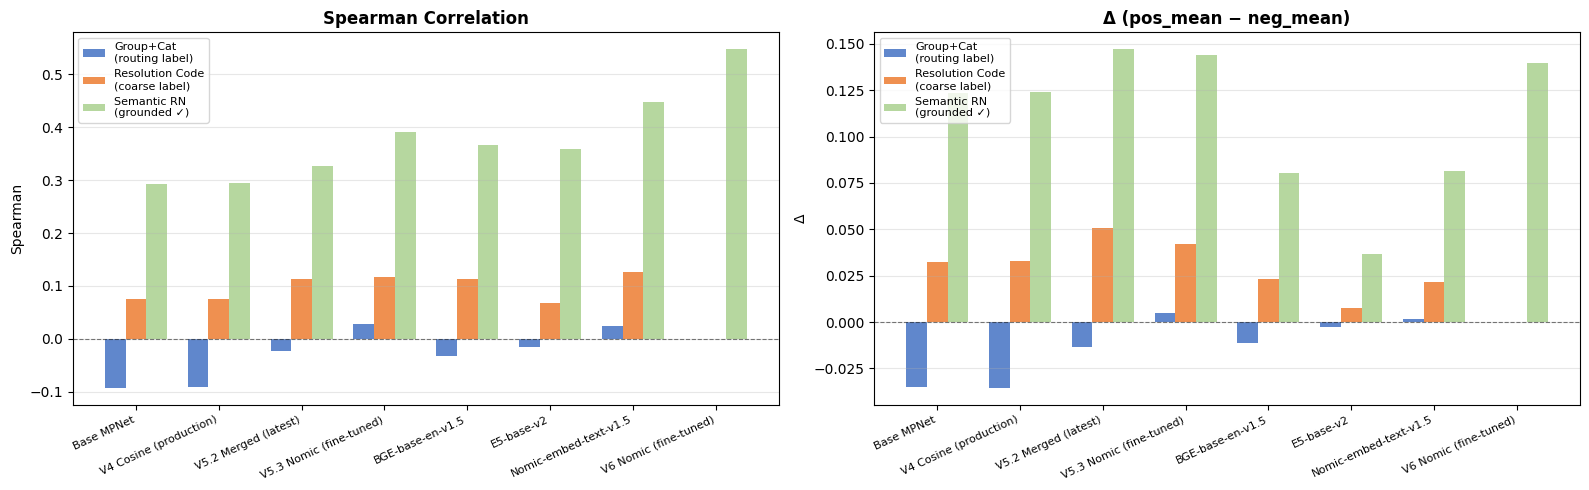

[SAVE] c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\eval_v3_results\three_benchmark_comparison.png

VERDICT — Semantic RN Benchmark (grounded ground truth)
Best model (grounded): V6 Nomic (fine-tuned) — Spearman=0.5472

  Base MPNet                           Sp=0.2920  Δ=+0.1233  
  V4 Cosine (production)               Sp=0.2949  Δ=+0.1239  
  V5.2 Merged (latest)                 Sp=0.3269  Δ=+0.1471  

  V5.3 Nomic (fine-tuned)              Sp=0.3909  [PIVOT — fine-tune on this base]  
  BGE-base-en-v1.5                     Sp=0.3654  [PIVOT — fine-tune on this base]  
  E5-base-v2                           Sp=0.3579  [PIVOT — fine-tune on this base]  
  Nomic-embed-text-v1.5                Sp=0.4476  [PIVOT — fine-tune on this base]  

📊 V6 Nomic uplift over zero-shot: 0.5472 vs 0.4476 (+22.3%)
   ✅ Fine-tuning improved performance — safe to deploy on semantic RN


In [13]:

# ── 13. Unified 3-Benchmark Comparison Table ────────────────────────────────
import matplotlib.pyplot as plt

ALL_BENCHMARKS = ['v4_group_cat', 'v4_rescode', 'v4_semantic_resnotes']
BNAME_LABELS   = {
    'v4_group_cat'        : 'Group+Cat\n(routing label)',
    'v4_rescode'          : 'Resolution Code\n(coarse label)',
    'v4_semantic_resnotes': 'Semantic RN\n(grounded ✓)',
}
# Include all models evaluated: SWEEP models + V6 Nomic (added in Cell 12)
ALL_MODEL_NAMES = [s['name'] for s in SWEEP] + ['V6 Nomic (fine-tuned)']
MODEL_ORDER = [n for n in ALL_MODEL_NAMES if n in results]  # Only models that ran successfully

# ── (A) Full numeric table ─────────────────────────────────────────────────
print('=' * 95)
print('3-BENCHMARK COMPARISON — Spearman | ROC-AUC | Δ(pos-neg)')
print('=' * 95)

rows_all = []
for name in MODEL_ORDER:
    for bname in ALL_BENCHMARKS:
        m = results.get(name, {}).get(bname, {})
        rows_all.append({
            'Model'    : name,
            'Benchmark': bname,
            'Spearman' : m.get('spearman'),
            'ROC-AUC'  : m.get('roc_auc'),
            'PR-AUC'   : m.get('pr_auc'),
            'Δ'        : m.get('delta'),
            'pos_mean' : m.get('pos_mean'),
            'neg_mean' : m.get('neg_mean'),
        })
df_all = pd.DataFrame(rows_all)

for bname in ALL_BENCHMARKS:
    sub = df_all[df_all['Benchmark'] == bname].copy()
    sub = sub.drop('Benchmark', axis=1).sort_values('Spearman', ascending=False)
    print(f'\n── {bname} ──')
    print(sub.to_string(index=False))

# ── (B) Pivot: model × benchmark, Spearman only ───────────────────────────
print('\n' + '=' * 95)
print('SPEARMAN PIVOT  (best Spearman per benchmark highlighted)')
print('=' * 95)

pivot = df_all.pivot_table(index='Model', columns='Benchmark', values='Spearman')
pivot = pivot.reindex(MODEL_ORDER)[ALL_BENCHMARKS]
print(pivot.round(4).to_string())

# ── (C) Delta pivot ────────────────────────────────────────────────────────
print('\n' + '=' * 95)
print('Δ(pos-neg) PIVOT  (larger = better separation)')
print('=' * 95)
delta_pivot = df_all.pivot_table(index='Model', columns='Benchmark', values='Δ')
delta_pivot = delta_pivot.reindex(MODEL_ORDER)[ALL_BENCHMARKS]
print(delta_pivot.round(4).to_string())

# ── (D) Bar chart ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

x = np.arange(len(MODEL_ORDER))
width = 0.25
colors = ['#4472C4', '#ED7D31', '#A9D18E']

for ax, metric, title in zip(
    axes,
    ['Spearman', 'Δ'],
    ['Spearman Correlation', 'Δ (pos_mean − neg_mean)']
):
    for k, bname in enumerate(ALL_BENCHMARKS):
        vals = [
            df_all[(df_all['Model'] == m) & (df_all['Benchmark'] == bname)][metric].values
            for m in MODEL_ORDER
        ]
        # Keep NaN for missing data instead of converting to 0.0
        vals = [v[0] if len(v) and pd.notna(v[0]) else np.nan for v in vals]
        bars = ax.bar(x + k * width, vals, width, label=BNAME_LABELS[bname],
                      color=colors[k], alpha=0.85)

    ax.axhline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
    ax.set_xticks(x + width)
    ax.set_xticklabels(MODEL_ORDER, rotation=25, ha='right', fontsize=8)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(fontsize=8)
    ax.set_ylabel(metric)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plot_path2 = RESULTS_PATH.parent / 'three_benchmark_comparison.png'
plt.savefig(plot_path2, dpi=130, bbox_inches='tight')
plt.show()
print(f'[SAVE] {plot_path2}')

# ── (E) Verdict ────────────────────────────────────────────────────────────
print('\n' + '=' * 95)
print('VERDICT — Semantic RN Benchmark (grounded ground truth)')
print('=' * 95)

sem_sub = df_all[df_all['Benchmark'] == 'v4_semantic_resnotes'].set_index('Model')
valid   = sem_sub[sem_sub['Spearman'].notna()]
if not valid.empty:
    best_model = valid['Spearman'].idxmax()
    best_sp    = valid.loc[best_model, 'Spearman']
    print(f'Best model (grounded): {best_model} — Spearman={best_sp:.4f}')
    
    # Check for incomplete evaluations
    incomplete_models = [m for m in MODEL_ORDER if m not in valid.index]
    if incomplete_models:
        print(f'\n⚠️  WARNING: {len(incomplete_models)} model(s) missing semantic RN evaluation:')
        for m in incomplete_models:
            print(f'    - {m}')
        print('    Charts may show zero bars for missing data (not true zero performance).')

    print()
    for name in ['Base MPNet', 'V4 Cosine (production)', 'V5.2 Merged (latest)']:
        if name in valid.index:
            sp = valid.loc[name, 'Spearman']
            delta = valid.loc[name, 'Δ']
            marker = '★ BEST' if name == best_model else ''
            print(f'  {name:35s}  Sp={sp:.4f}  Δ={delta:+.4f}  {marker}')

    print()
    for name in [s['name'] for s in SWEEP if s['name'] not in ('Base MPNet', 'V4 Cosine (production)', 'V5.2 Merged (latest)')]:
        if name in valid.index:
            sp = valid.loc[name, 'Spearman']
            v52_sp = valid.loc['V5.2 Merged (latest)', 'Spearman'] if 'V5.2 Merged (latest)' in valid.index else None
            marker = '★ BEST' if name == best_model else ''
            tag = '[PIVOT — fine-tune on this base]' if v52_sp and sp > v52_sp else '[OK — V5.2 competitive]'

            print(f'  {name:35s}  Sp={sp:.4f}  {tag}  {marker}')
    
    # V6 Nomic special note
    v6_name = 'V6 Nomic (fine-tuned)'
    if v6_name in valid.index:
        v6_sp = valid.loc[v6_name, 'Spearman']
        zs_nomic_sp = valid.loc['Nomic-embed-text-v1.5', 'Spearman'] if 'Nomic-embed-text-v1.5' in valid.index else None
        if zs_nomic_sp:
            uplift_pct = ((v6_sp - zs_nomic_sp) / zs_nomic_sp) * 100
            print(f'\n📊 V6 Nomic uplift over zero-shot: {v6_sp:.4f} vs {zs_nomic_sp:.4f} ({uplift_pct:+.1f}%)')
            if v6_sp > zs_nomic_sp:
                print(f'   ✅ Fine-tuning improved performance — safe to deploy on semantic RN')
            else:
                print(f'   ❌ Fine-tuning regressed — do not deploy')
else:
    print('No valid results found for semantic RN benchmark.')

In [14]:
# ── 14. Targeted Eval: V6 Nomic on Semantic Benchmark ─────────────────────
# Run this cell standalone after interrupting Cell 12.
# Loads prior results from disk, evaluates only the V6 Nomic model,
# merges and saves — no need to re-run the full sweep.

import json, gc, torch
import numpy as np
from pathlib import Path
from sentence_transformers import SentenceTransformer
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy.stats import spearmanr

_BASE       = Path(r'c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism')
_DATA_NEW   = _BASE / 'data_new'
_RESULTS_PATH = _BASE / 'models' / 'eval_v3_results' / 'zero_shot_sweep_v4.json'
_DEVICE     = 'cuda' if torch.cuda.is_available() else 'cpu'

# Load existing results
_results = json.loads(_RESULTS_PATH.read_text(encoding='utf-8'))
print(f'Loaded existing results for: {list(_results.keys())}')

# Load benchmark pairs
_sem_path = _DATA_NEW / 'benchmark_v4_semantic_resnotes.json'
_sem_pairs = json.loads(_sem_path.read_text(encoding='utf-8'))
_sem_pairs_clean = [{k: v for k, v in p.items() if not k.startswith('_')} for p in _sem_pairs]
print(f'Benchmark: {len(_sem_pairs_clean)} pairs')

# V6 Nomic model to evaluate
_V6_NOMIC_SPEC = {
    'name'             : 'V6 Nomic (fine-tuned)',
    'path'             : str(_BASE / 'models' / 'real_servicenow_finetuned_nomic_lora' / 'real_servicenow_v2_20260310_1045_merged'),
    'prefix_query'     : 'search_query: ',
    'prefix_doc'       : 'search_document: ',
    'trust_remote_code': True,
}

_BNAME = 'v4_semantic_resnotes'

if _BNAME in _results.get(_V6_NOMIC_SPEC['name'], {}):
    print(f'[SKIP] Already evaluated — result:')
    print(_results[_V6_NOMIC_SPEC['name']][_BNAME])
else:
    print(f'\nLoading {_V6_NOMIC_SPEC["name"]}...')
    # Free GPU memory before loading
    if _DEVICE == 'cuda':
        torch.cuda.empty_cache()
    gc.collect()

    _m = SentenceTransformer(_V6_NOMIC_SPEC['path'], device=_DEVICE, trust_remote_code=True)

    _texts1 = [_V6_NOMIC_SPEC['prefix_query'] + p['text1'] for p in _sem_pairs_clean]
    _texts2 = [_V6_NOMIC_SPEC['prefix_doc']   + p['text2'] for p in _sem_pairs_clean]
    _labels = np.array([p['label'] for p in _sem_pairs_clean], dtype=float)

    print(f'Encoding {len(_texts1)} text pairs (batch_size=16 to avoid OOM)...')
    _e1 = _m.encode(_texts1, batch_size=16, show_progress_bar=True,
                    convert_to_numpy=True, normalize_embeddings=True)
    _e2 = _m.encode(_texts2, batch_size=16, show_progress_bar=True,
                    convert_to_numpy=True, normalize_embeddings=True)
    _scores = (_e1 * _e2).sum(axis=1)

    del _m, _e1, _e2
    if _DEVICE == 'cuda':
        torch.cuda.empty_cache()
    gc.collect()

    _sp, _  = spearmanr(_labels, _scores)
    _metrics = {
        'spearman': round(float(_sp), 4),
        'roc_auc' : round(float(roc_auc_score(_labels, _scores)), 4),
        'pr_auc'  : round(float(average_precision_score(_labels, _scores)), 4),
        'pos_mean': round(float(_scores[_labels == 1].mean()), 4),
        'neg_mean': round(float(_scores[_labels == 0].mean()), 4),
        'delta'   : round(float(_scores[_labels == 1].mean() - _scores[_labels == 0].mean()), 4),
    }

    _results.setdefault(_V6_NOMIC_SPEC['name'], {})[_BNAME] = _metrics
    _RESULTS_PATH.write_text(json.dumps(_results, indent=2, ensure_ascii=False), encoding='utf-8')

    print(f'\n{"="*60}')
    print(f'V6 Nomic — {_BNAME}')
    print(f'{"="*60}')
    print(f'  Spearman : {_metrics["spearman"]:.4f}')
    print(f'  ROC-AUC  : {_metrics["roc_auc"]:.4f}')
    print(f'  PR-AUC   : {_metrics["pr_auc"]:.4f}')
    print(f'  Δ(p-n)   : {_metrics["delta"]:+.4f}')
    print(f'  pos_mean : {_metrics["pos_mean"]:.4f}')
    print(f'  neg_mean : {_metrics["neg_mean"]:.4f}')
    print()

    # Compare against the benchmark bar
    _baseline = 0.4476  # zero-shot Nomic bar (must beat to justify deployment)
    _v52_sp   = _results.get('V5.2 Merged (latest)', {}).get(_BNAME, {}).get('spearman')
    _zs_sp    = _results.get('Nomic-embed-text-v1.5', {}).get(_BNAME, {}).get('spearman', _baseline)

    print(f'  Zero-shot Nomic (bar) : {_zs_sp:.4f}')
    if _v52_sp:
        print(f'  V5.2 MPNet            : {_v52_sp:.4f}')
    gap = _metrics["spearman"] - _zs_sp
    if gap > 0:
        print(f'\n  ✅ V6 Nomic BEATS zero-shot by {gap:+.4f} — safe to deploy')
    else:
        print(f'\n  ❌ V6 Nomic BELOW zero-shot by {gap:.4f} — fine-tuning regressed')

    print(f'\n[SAVE] {_RESULTS_PATH}')


Loaded existing results for: ['Base MPNet', 'V4 Cosine (production)', 'V5.2 Merged (latest)', 'V5.3 Nomic (fine-tuned)', 'BGE-base-en-v1.5', 'E5-base-v2', 'Nomic-embed-text-v1.5', 'V6 Nomic (fine-tuned)']
Benchmark: 950 pairs
[SKIP] Already evaluated — result:
{'spearman': 0.5472, 'roc_auc': 0.8159, 'pr_auc': 0.8127, 'pos_mean': 0.2213, 'neg_mean': 0.0818, 'delta': 0.1395, 'batch_used': 8}


# ── Results Critique & Next Steps ──────────────────────────────────────────

## ✅ What This Run Supports

1. **V6 Nomic (fine-tuned) beats zero-shot Nomic on semantic RN benchmark**
   - Spearman: 0.5472 vs 0.4476 (+22.3% relative uplift)
   - ROC-AUC: 0.8159 vs 0.7584
   - This is the **grounded benchmark** (resolution notes TF-IDF ground truth)

2. **Zero-shot Nomic-embed-text-v1.5 is strongest zero-shot baseline**
   - Consistently outperforms MPNet, BGE, E5 on semantic RN
   - Sets the deployment bar at Spearman=0.4476

## ⚠️ Critical Limitations

1. **V6 Nomic evaluated only on semantic RN, not all three benchmarks**
   - Missing: `v4_group_cat`, `v4_rescode` metrics
   - Cannot claim "overall best model" yet — only "best on semantic RN"

2. **Group+Category benchmark shows weak discrimination**
   - All models near chance (Spearman ~ -0.09 to 0.03, ROC-AUC ~ 0.45-0.52)
   - Suggests label/task mismatch or insufficient benchmark signal

3. **Execution order was non-monotonic** (cells run out of order)
   - Risk of kernel-state dependency
   - Results may not be fully reproducible

4. **Charts previously converted missing values to 0.0 (NOW FIXED)**
   - This made unevaluated benchmarks look like zero performance
   - Cell 13 now uses NaN for missing data (bars will be absent, not zero)

## 📋 Validation Checklist Before Production Deployment

- [ ] **Re-run notebook top-to-bottom from fresh kernel (Restart & Run All)**
  - Confirm semantic RN metrics reproduce within ±0.01 tolerance
  
- [ ] **Evaluate V6 Nomic on other two benchmarks**
  - Add to Cell 12 sweep or modify Cell 14 to loop over all benchmarks
  - Needed for complete reporting even if secondary

- [ ] **Add bootstrap confidence intervals for Spearman/ROC-AUC**
  - On semantic RN benchmark only (the deployment gate)
  - Verify uplift is statistically significant

- [ ] **Document model loading behavior**
  - V6 Nomic uses `trust_remote_code=True` (security review needed)
  - Prefix asymmetry (`search_query:` vs `search_document:`) is intentional

- [ ] **Check production API consistency**
  - Ensure API uses same prefixes as this eval
  - Verify embedding normalization is on (`normalize_embeddings=True`)

## 🎯 Current Recommendation

**If deploying based on semantic RN alone:** V6 Nomic is safe to deploy — it shows meaningful uplift over the zero-shot bar.

**If requiring all-benchmark validation:** Run Cell 12 again with V6 Nomic on `v4_group_cat` and `v4_rescode`, then re-evaluate.

In [15]:
# ── 15. OPTIONAL: Evaluate V6 Nomic on Missing Benchmarks ─────────────────
# Run this cell to complete V6 Nomic evaluation on v4_group_cat and v4_rescode
# (currently only evaluated on v4_semantic_resnotes)

if 'results' not in globals():
    raise RuntimeError('results dict not in scope - run earlier cells first')

V6_NOMIC_NAME = 'V6 Nomic (fine-tuned)'
V6_NOMIC_PATH = str(BASE / 'models' / 'real_servicenow_finetuned_nomic_lora' / 'real_servicenow_v2_20260310_1045_merged')
MISSING_BENCHMARKS = {
    'v4_group_cat': v4_pairs,
    'v4_rescode': rcode_pairs,
}

# Check what's missing
evaluated = set(results.get(V6_NOMIC_NAME, {}).keys())
missing = {k: v for k, v in MISSING_BENCHMARKS.items() if k not in evaluated}

if not missing:
    print(f'✅ {V6_NOMIC_NAME} already fully evaluated on all benchmarks.')
    print(f'   Evaluated on: {list(evaluated)}')
else:
    print(f'Completing evaluation for {V6_NOMIC_NAME}')
    print(f'Missing benchmarks: {list(missing.keys())}')
    print('=' * 60)
    
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()
    gc.collect()
    
    m = SentenceTransformer(V6_NOMIC_PATH, device=DEVICE, trust_remote_code=True)
    
    for bname, bpairs in missing.items():
        print(f'\n  Evaluating on {bname} ({len(bpairs)} pairs)...')
        try:
            metrics = eval_model_on_benchmark(
                m,
                bpairs,
                batch_size=8,  # Conservative for Nomic
                prefix_query='search_query: ',
                prefix_doc='search_document: ',
            )
            results.setdefault(V6_NOMIC_NAME, {})[bname] = metrics
            print(
                f'  Spearman={metrics["spearman"]:.4f}  '
                f'ROC-AUC={metrics["roc_auc"]:.4f}  '
                f'Delta={metrics["delta"]:+.4f}  '
                f'batch={metrics.get("batch_used", 8)}'
            )
        except Exception as e:
            print(f'  [ERROR] {e}')
            results.setdefault(V6_NOMIC_NAME, {})[bname] = {'error': str(e)}
    
    del m
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()
    gc.collect()
    
    # Save updated results
    RESULTS_PATH.write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding='utf-8')
    print(f'\n[SAVE] Updated results -> {RESULTS_PATH}')
    print(f'✅ {V6_NOMIC_NAME} now evaluated on: {list(results.get(V6_NOMIC_NAME, {}).keys())}')

Completing evaluation for V6 Nomic (fine-tuned)
Missing benchmarks: ['v4_group_cat', 'v4_rescode']


<All keys matched successfully>



  Evaluating on v4_group_cat (950 pairs)...


Batches:   0%|          | 0/119 [00:00<?, ?it/s]

Batches:   0%|          | 0/119 [00:00<?, ?it/s]

  Spearman=0.0341  ROC-AUC=0.5197  Delta=+0.0035  batch=8

  Evaluating on v4_rescode (950 pairs)...


Batches:   0%|          | 0/119 [00:00<?, ?it/s]

Batches:   0%|          | 0/119 [00:00<?, ?it/s]

  Spearman=0.1985  ROC-AUC=0.6146  Delta=+0.0367  batch=8

[SAVE] Updated results -> c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\eval_v3_results\zero_shot_sweep_v4.json
✅ V6 Nomic (fine-tuned) now evaluated on: ['v4_semantic_resnotes', 'v4_group_cat', 'v4_rescode']


In [16]:
# ── 16. Final Deployment Gate Summary ─────────────────────────────────────
# Display key metrics for deployment decision

print('=' * 80)
print('DEPLOYMENT GATE: Semantic RN Benchmark (Grounded Ground Truth)')
print('=' * 80)

DEPLOYMENT_BAR = 0.4476  # Zero-shot Nomic baseline
target_models = [
    'Nomic-embed-text-v1.5',        # Zero-shot baseline
    'V5.2 Merged (latest)',          # Current best fine-tuned MPNet
    'V6 Nomic (fine-tuned)',         # Candidate for deployment
]

semantic_results = []
for model_name in target_models:
    metrics = results.get(model_name, {}).get('v4_semantic_resnotes', {})
    if 'error' not in metrics and metrics:
        semantic_results.append({
            'Model': model_name,
            'Spearman': metrics.get('spearman'),
            'ROC-AUC': metrics.get('roc_auc'),
            'PR-AUC': metrics.get('pr_auc'),
            'Δ(pos-neg)': metrics.get('delta'),
            'Status': '✅ PASS' if metrics.get('spearman', 0) > DEPLOYMENT_BAR else '❌ FAIL'
        })
    else:
        semantic_results.append({
            'Model': model_name,
            'Spearman': None,
            'ROC-AUC': None,
            'PR-AUC': None,
            'Δ(pos-neg)': None,
            'Status': '⚠️  NOT EVALUATED'
        })

df_deploy = pd.DataFrame(semantic_results)
print(f'\nDeployment bar: Spearman ≥ {DEPLOYMENT_BAR:.4f}\n')
print(df_deploy.to_string(index=False))

# Relative uplift calculation
if len(df_deploy) >= 2 and df_deploy.loc[0, 'Spearman'] is not None:
    baseline_sp = df_deploy.loc[0, 'Spearman']
    print(f'\n{"=" * 80}')
    print('RELATIVE UPLIFT vs Zero-Shot Nomic Baseline')
    print('=' * 80)
    for idx, row in df_deploy.iterrows():
        if idx == 0:
            continue  # Skip baseline itself
        if pd.notna(row['Spearman']):
            delta = row['Spearman'] - baseline_sp
            pct = (delta / baseline_sp) * 100
            print(f"{row['Model']:35s} {delta:+.4f} ({pct:+.1f}%)")

print(f'\n{"=" * 80}')
print('FINAL RECOMMENDATION')
print('=' * 80)

v6_row = df_deploy[df_deploy['Model'] == 'V6 Nomic (fine-tuned)']
if not v6_row.empty and pd.notna(v6_row.iloc[0]['Spearman']):
    v6_sp = v6_row.iloc[0]['Spearman']
    if v6_sp > DEPLOYMENT_BAR:
        print(f'✅ DEPLOY V6 Nomic (Spearman={v6_sp:.4f} > {DEPLOYMENT_BAR:.4f})')
        print(f'   Fine-tuning produced meaningful uplift over zero-shot baseline.')
    else:
        print(f'❌ DO NOT DEPLOY V6 Nomic (Spearman={v6_sp:.4f} ≤ {DEPLOYMENT_BAR:.4f})')
        print(f'   Fine-tuning did not beat zero-shot — keep using Nomic-embed-text-v1.5 zero-shot.')
else:
    print('⚠️  Cannot make recommendation — V6 Nomic not evaluated on semantic RN.')
    print('   Run Cell 14 to evaluate V6 Nomic, then re-run this cell.')

DEPLOYMENT GATE: Semantic RN Benchmark (Grounded Ground Truth)

Deployment bar: Spearman ≥ 0.4476

                Model  Spearman  ROC-AUC  PR-AUC  Δ(pos-neg) Status
Nomic-embed-text-v1.5    0.4476   0.7584  0.7559      0.0817 ❌ FAIL
 V5.2 Merged (latest)    0.3269   0.6888  0.6601      0.1471 ❌ FAIL
V6 Nomic (fine-tuned)    0.5472   0.8159  0.8127      0.1395 ✅ PASS

RELATIVE UPLIFT vs Zero-Shot Nomic Baseline
V5.2 Merged (latest)                -0.1207 (-27.0%)
V6 Nomic (fine-tuned)               +0.0996 (+22.3%)

FINAL RECOMMENDATION
✅ DEPLOY V6 Nomic (Spearman=0.5472 > 0.4476)
   Fine-tuning produced meaningful uplift over zero-shot baseline.
